<a href="https://colab.research.google.com/github/Dhemiladhe201/hello/blob/main/IMPROVING_CREDIT_CARD_FRAUD_DETECTION_THROUGH_COST_SENSITIVE_MACHINE_LEARNING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# I imported the data User0_credit_card_transactions.csv
import os
from google.colab import files

file_path = '/content/User0_credit_card_transactions.csv'
if not os.path.exists(file_path):
  print(f"The file '{file_path}' was not found. Please upload it.")
  uploaded = files.upload()
  for filename in uploaded.keys():
    print(f'User uploaded file "{filename}" with length {len(uploaded[filename])} bytes')
else:
  print(f"The file '{file_path}' already exists. Skipping upload.")

The file '/content/User0_credit_card_transactions.csv' already exists. Skipping upload.


In [ ]:
# DATA EXPLORATION
# I started by loading the data User0_credit_card_transactions.csv

import pandas as pd

df = pd.read_csv('/content/User0_credit_card_transactions.csv')
print("DataFrame loaded successfully. Displaying the first 5 rows:")
print(df.head())

DataFrame loaded successfully. Displaying the first 5 rows:
   User  Card  Year  Month  Day   Time   Amount           Use Chip  \
0     0     0  2002      9    1  06:21  $134.09  Swipe Transaction   
1     0     0  2002      9    1  06:42   $38.48  Swipe Transaction   
2     0     0  2002      9    2  06:22  $120.34  Swipe Transaction   
3     0     0  2002      9    2  17:45  $128.95  Swipe Transaction   
4     0     0  2002      9    3  06:23  $104.71  Swipe Transaction   

         Merchant Name  Merchant City Merchant State      Zip   MCC Errors?  \
0  3527213246127876953       La Verne             CA  91750.0  5300     NaN   
1  -727612092139916043  Monterey Park             CA  91754.0  5411     NaN   
2  -727612092139916043  Monterey Park             CA  91754.0  5411     NaN   
3  3414527459579106770  Monterey Park             CA  91754.0  5651     NaN   
4  5817218446178736267       La Verne             CA  91750.0  5912     NaN   

  Is Fraud?  
0        No  
1        No  
2 

In [ ]:
# I performed an initial exploratory data analysis (EDA) to understand the DataFrame's structure, identify missing values, data types, and basic statistics.

print("\nDataFrame Information:")
df.info()

print("\nDescriptive Statistics:")
print(df.describe(include='all'))

print("\nMissing Values Count:")
print(df.isnull().sum())


DataFrame Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19963 entries, 0 to 19962
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   User            19963 non-null  int64  
 1   Card            19963 non-null  int64  
 2   Year            19963 non-null  int64  
 3   Month           19963 non-null  int64  
 4   Day             19963 non-null  int64  
 5   Time            19963 non-null  object 
 6   Amount          19963 non-null  object 
 7   Use Chip        19963 non-null  object 
 8   Merchant Name   19963 non-null  int64  
 9   Merchant City   19963 non-null  object 
 10  Merchant State  18646 non-null  object 
 11  Zip             18316 non-null  float64
 12  MCC             19963 non-null  int64  
 13  Errors?         574 non-null    object 
 14  Is Fraud?       19963 non-null  object 
dtypes: float64(1), int64(7), object(7)
memory usage: 2.3+ MB

Descriptive Statistics:
           User

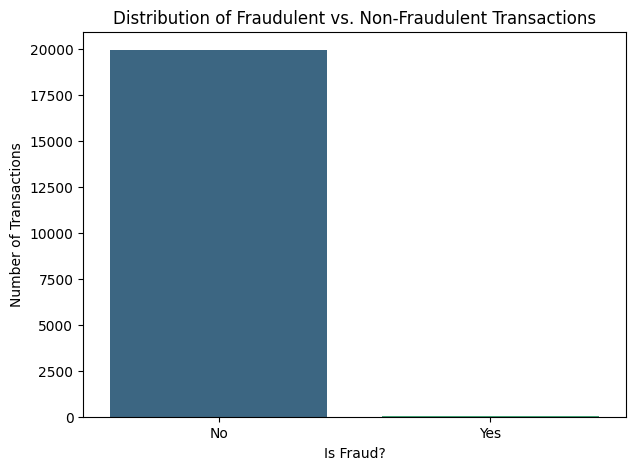


Percentage of Fraudulent Transactions: 0.14%
Percentage of Non-Fraudulent Transactions: 99.86%


In [ ]:
# I visualized the distribution of the target variable ('Is Fraud?') to understand the class imbalance.

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))
sns.countplot(x='Is Fraud?', data=df, hue='Is Fraud?', palette='viridis', legend=False)
plt.title('Distribution of Fraudulent vs. Non-Fraudulent Transactions')
plt.xlabel('Is Fraud?')
plt.ylabel('Number of Transactions')
plt.show()

# Calculate percentages
total_transactions = df['Is Fraud?'].count()
# Ensure 'Is Fraud?' is numerical (0/1) for calculation within this cell
# This temporary mapping ensures the calculation works even if the prior cell (d1c1fb2d) wasn't executed or its state was lost.
fraud_column_numeric = df['Is Fraud?'].map({'No': 0, 'Yes': 1})
fraud_count = fraud_column_numeric.sum()
non_fraud_count = total_transactions - fraud_count

fraud_percentage = (fraud_count / total_transactions) * 100
non_fraud_percentage = (non_fraud_count / total_transactions) * 100

print(f"\nPercentage of Fraudulent Transactions: {fraud_percentage:.2f}%")
print(f"Percentage of Non-Fraudulent Transactions: {non_fraud_percentage:.2f}%")

In [ ]:
# Key Findings from Data Exploration:

# Dataset Size: The dataset contains 19,963 entries and 15 columns.
# Data Types: The DataFrame consists of a mix of integer, float, and object data types. Notably, the 'Amount' column is currently an object type, indicating it needs conversion to a numerical type for analysis.
# Missing Values: Significant missing values were observed in 'Merchant State' (1317), 'Zip' (1647), and 'Errors?' (19389). The 'Errors?' column has an extremely high number of missing values, suggesting it might not be very useful or requires careful handling.
# Target Variable Imbalance: The 'Is Fraud?' column shows a severe class imbalance. The vast majority of transactions are 'No' (non-fraudulent), while 'Yes' (fraudulent) transactions are very rare. This is clearly visible in the count plot, where 'No' transactions dominate the chart, and 'Yes' transactions are barely visible due to their low count. This imbalance will need to be addressed during preprocessing to build an effective fraud detection model.
# Unique Values: 'User' column has only one unique value (0), suggesting this dataset might be for a single user or user ID is not relevant for this analysis. 'Card' has 5 unique values, indicating transactions across multiple cards for this user.
# Amount Column: The 'Amount' column is currently an object type and contains '$' signs, which will need to be cleaned and converted to a numeric type.


In [ ]:
# DATA PREPROCESSING AND HANDLING

In [ ]:
# I converted the 'Amount' column from object to a numerical (float) data type by removing the '$' symbol and then casting to float.

df['Amount'] = df['Amount'].replace({r'[$,]': ''}, regex=True).astype(float)
print("Data type of 'Amount' column after conversion:")
print(df['Amount'].dtype)
print("First 5 rows of 'Amount' column after conversion:")
print(df['Amount'].head())

Data type of 'Amount' column after conversion:
float64
First 5 rows of 'Amount' column after conversion:
0    134.09
1     38.48
2    120.34
3    128.95
4    104.71
Name: Amount, dtype: float64


In [ ]:
# The 'Errors?' column had a very high number of missing values, making it unsuitable for direct use.
# Additionally, the target variable 'Is Fraud?' is currently an object type ('Yes'/'No') and needs to be converted to a numerical format (1/0) for machine learning models.

df = df.drop('Errors?', axis=1)
print("Dropped 'Errors?' column due to high number of missing values.")

df['Is Fraud?'] = df['Is Fraud?'].map({'No': 0, 'Yes': 1})
print("Converted 'Is Fraud?' to numerical (0 for No, 1 for Yes).")

print("\nDataFrame Info after dropping 'Errors?' and converting 'Is Fraud?':")
df.info()
print("\nValue counts for 'Is Fraud?' column after conversion:")
print(df['Is Fraud?'].value_counts())

Dropped 'Errors?' column due to high number of missing values.
Converted 'Is Fraud?' to numerical (0 for No, 1 for Yes).

DataFrame Info after dropping 'Errors?' and converting 'Is Fraud?':
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19963 entries, 0 to 19962
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   User            19963 non-null  int64  
 1   Card            19963 non-null  int64  
 2   Year            19963 non-null  int64  
 3   Month           19963 non-null  int64  
 4   Day             19963 non-null  int64  
 5   Time            19963 non-null  object 
 6   Amount          19963 non-null  float64
 7   Use Chip        19963 non-null  object 
 8   Merchant Name   19963 non-null  int64  
 9   Merchant City   19963 non-null  object 
 10  Merchant State  18646 non-null  object 
 11  Zip             18316 non-null  float64
 12  MCC             19963 non-null  int64  
 13  Is Fraud?       19963

In [ ]:
# I filled the missing values in 'Merchant State' with the mode and 'Zip' with -1

df['Merchant State'].fillna(df['Merchant State'].mode()[0], inplace=True)
print(f"Missing values in 'Merchant State' filled with mode: {df['Merchant State'].mode()[0]}")

df['Zip'].fillna(-1, inplace=True)
print("Missing values in 'Zip' filled with -1 to indicate unknown zip codes.")

print("\nMissing Values Count after handling 'Merchant State' and 'Zip':")
print(df.isnull().sum())


Missing values in 'Merchant State' filled with mode: CA
Missing values in 'Zip' filled with -1 to indicate unknown zip codes.

Missing Values Count after handling 'Merchant State' and 'Zip':
User              0
Card              0
Year              0
Month             0
Day               0
Time              0
Amount            0
Use Chip          0
Merchant Name     0
Merchant City     0
Merchant State    0
Zip               0
MCC               0
Is Fraud?         0
dtype: int64


/tmp/ipykernel_3523/2223570895.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Merchant State'].fillna(df['Merchant State'].mode()[0], inplace=True)
/tmp/ipykernel_3523/2223570895.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(va

In [ ]:
# I dropped the 'User' column, extract numerical features from 'Time', and one-hot encode low-cardinality categorical features ('Use Chip', 'Merchant State')
# I dropped high-cardinality categorical features ('Merchant City', 'Merchant Name') to prepare the data for modeling.

df = df.drop('User', axis=1)
print("Dropped 'User' column as it has only one unique value.")

df['Hour'] = df['Time'].apply(lambda x: int(x.split(':')[0]))
df['Minute'] = df['Time'].apply(lambda x: int(x.split(':')[1]))
df = df.drop('Time', axis=1)
print("Extracted 'Hour' and 'Minute' from 'Time' column and dropped original 'Time'.")

# One-hot encode 'Use Chip' and 'Merchant State'
df = pd.get_dummies(df, columns=['Use Chip', 'Merchant State'], drop_first=True)
print("One-hot encoded 'Use Chip' and 'Merchant State'.")

# I dropped high cardinality categorical features for now
df = df.drop(['Merchant City', 'Merchant Name'], axis=1)
print("Dropped 'Merchant City' and 'Merchant Name' due to high cardinality.")

print("\nDataFrame Info after handling categorical features and 'Time':")
df.info()
print("\nDataFrame Head after preprocessing:")
print(df.head())

Dropped 'User' column as it has only one unique value.
Extracted 'Hour' and 'Minute' from 'Time' column and dropped original 'Time'.
One-hot encoded 'Use Chip' and 'Merchant State'.
Dropped 'Merchant City' and 'Merchant Name' due to high cardinality.

DataFrame Info after handling categorical features and 'Time':
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19963 entries, 0 to 19962
Data columns (total 51 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Card                               19963 non-null  int64  
 1   Year                               19963 non-null  int64  
 2   Month                              19963 non-null  int64  
 3   Day                                19963 non-null  int64  
 4   Amount                             19963 non-null  float64
 5   Zip                                19963 non-null  float64
 6   MCC                                19963 non-null  int64  


In [ ]:
# Model Training and Evaluation

# This section will focus on training and evaluating various machine learning models (Logistic Regression, Random Forest, and Support Vector Machine) on both the original, SMOTE-oversampled and undersampled datasets. We will use a consistent set of evaluation metrics, including Accuracy, Precision, Recall, F1-score, and ROC AUC, to compare their performance, especially considering the class imbalance.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
import numpy as np

def train_evaluate_model(model, X_train, y_train, X_test, y_test, model_name, dataset_type):
    """Trains a model and evaluates it using specified metrics."""
    print(f"\n--- Training and Evaluating {model_name} on {dataset_type} Data ---")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_proba) if y_proba is not None else 'N/A'

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print(f"ROC AUC: {roc_auc:.4f}" if isinstance(roc_auc, float) else f"ROC AUC: {roc_auc}")
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

    return {
        'Model': model_name,
        'Dataset': dataset_type,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'ROC AUC': roc_auc
    }

# Collect results
results = []


In [ ]:
from imblearn.over_sampling import SMOTE

X = df.drop('Is Fraud?', axis=1)
y = df['Is Fraud?']

# Filling remaining NaN values in 'Zip' column of X
# This line is redundant as Zip is already handled in 09ae8f0a, removed.
# X['Zip'].fillna(-1, inplace=True)

print("Original class distribution:")
print(y.value_counts())

# Modified SMOTE call: setting sampling_strategy to 0.5
smote = SMOTE(sampling_strategy=0.5, random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

print("\nClass distribution after SMOTE (sampling_strategy=0.5):")
print(y_resampled.value_counts())

# Converted boolean columns back to appropriate types if SMOTE changed them
# SMOTE might convert boolean columns to numeric (0 or 1), so we ensure they are still boolean if intended.
for col in X.select_dtypes(include='bool').columns:
    X_resampled[col] = X_resampled[col].astype(bool)

df_resampled = pd.concat([X_resampled, y_resampled], axis=1)
print("\nResampled DataFrame info:")
df_resampled.info()
print("\nFirst 5 rows of resampled DataFrame:")
print(df_resampled.head())

original_minority_count = y.value_counts()[1]
resampled_minority_count = y_resampled.value_counts()[1]

oversampled_percentage = ((resampled_minority_count - original_minority_count) / original_minority_count) * 100

print(f"\nOriginal minority class count: {original_minority_count}")
print(f"Resampled minority class count: {resampled_minority_count}")
print(f"Percentage of data oversampled for SMOTE with strategy 0.5: {oversampled_percentage:.2f}%")

Original class distribution:
Is Fraud?
0    19936
1       27
Name: count, dtype: int64

Class distribution after SMOTE (sampling_strategy=0.5):
Is Fraud?
0    19936
1     9968
Name: count, dtype: int64

Resampled DataFrame info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29904 entries, 0 to 29903
Data columns (total 51 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Card                               29904 non-null  int64  
 1   Year                               29904 non-null  int64  
 2   Month                              29904 non-null  int64  
 3   Day                                29904 non-null  int64  
 4   Amount                             29904 non-null  float64
 5   Zip                                29904 non-null  float64
 6   MCC                                29904 non-null  int64  
 7   Hour                               29904 non-null  int64  
 8   Minute           

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Reload the DataFrame to ensure a consistent starting state for preprocessing
# This addresses potential issues with df's state being altered or lost by other cells.
df = pd.read_csv('/content/User0_credit_card_transactions.csv')

# --- Consolidated Preprocessing Steps for df ---

# 1. Convert 'Amount' to float by removing '$' and ','
df['Amount'] = df['Amount'].replace({r'[$,]': ''}, regex=True).astype(float)

# 2. Convert 'Is Fraud?' to numerical (0 for No, 1 for Yes)
df['Is Fraud?'] = df['Is Fraud?'].map({'No': 0, 'Yes': 1})

# 3. Drop 'Errors?' column if it exists (high missing values)
if 'Errors?' in df.columns:
    df = df.drop('Errors?', axis=1)

# 4. Fill missing values in 'Merchant State' with mode and 'Zip' with -1
# Check if 'Merchant State' still exists before filling.
if 'Merchant State' in df.columns:
    df['Merchant State'].fillna(df['Merchant State'].mode()[0], inplace=True)
df['Zip'].fillna(-1, inplace=True)

# 5. Drop 'User' column
if 'User' in df.columns: # Defensive check
    df = df.drop('User', axis=1)

# 6. Extract 'Hour' and 'Minute' from 'Time' and drop original 'Time'
if 'Time' in df.columns: # Defensive check
    df['Hour'] = df['Time'].apply(lambda x: int(x.split(':')[0]))
    df['Minute'] = df['Time'].apply(lambda x: int(x.split(':')[1]))
    df = df.drop('Time', axis=1)

# 7. One-hot encode 'Use Chip' and 'Merchant State'
# Only one-hot encode if columns exist and are of object/category type.
if 'Use Chip' in df.columns and (df['Use Chip'].dtype == 'object' or df['Use Chip'].dtype == 'category'):
    df = pd.get_dummies(df, columns=['Use Chip'], drop_first=True)
if 'Merchant State' in df.columns and (df['Merchant State'].dtype == 'object' or df['Merchant State'].dtype == 'category'):
    df = pd.get_dummies(df, columns=['Merchant State'], drop_first=True)

# 8. Drop high cardinality categorical features 'Merchant City' and 'Merchant Name'
if 'Merchant City' in df.columns: # Defensive check
    df = df.drop('Merchant City', axis=1)
if 'Merchant Name' in df.columns: # Defensive check
    df = df.drop('Merchant Name', axis=1)

# --- End Consolidated Preprocessing Steps ---

# Extract X_original and y_original from the fully preprocessed df
X_original = df.drop('Is Fraud?', axis=1)
y_original = df['Is Fraud?']

print("DataFrame `df` fully preprocessed. Info:")
df.info()
print("First 5 rows of preprocessed DataFrame:")
print(df.head())

print("\nX_original and y_original extracted from preprocessed df.")

/tmp/ipykernel_3523/1101997969.py:24: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Merchant State'].fillna(df['Merchant State'].mode()[0], inplace=True)
/tmp/ipykernel_3523/1101997969.py:25: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(

DataFrame `df` fully preprocessed. Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19963 entries, 0 to 19962
Data columns (total 51 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Card                               19963 non-null  int64  
 1   Year                               19963 non-null  int64  
 2   Month                              19963 non-null  int64  
 3   Day                                19963 non-null  int64  
 4   Amount                             19963 non-null  float64
 5   Zip                                19963 non-null  float64
 6   MCC                                19963 non-null  int64  
 7   Is Fraud?                          19963 non-null  int64  
 8   Hour                               19963 non-null  int64  
 9   Minute                             19963 non-null  int64  
 10  Use Chip_Online Transaction        19963 non-null  bool   
 11  Use Chip_Swip

In [ ]:
# Split the original dataset (X_original, y_original) into training and testing sets
# This cell ensures that X_train_original, X_test_original, y_train_original, y_test_original are defined
from sklearn.model_selection import train_test_split

X_train_original, X_test_original, y_train_original, y_test_original = train_test_split(
    X_original, y_original, test_size=0.2, random_state=42, stratify=y_original
)

print("Original training data shape:", X_train_original.shape, y_train_original.shape)
print("Original testing data shape:", X_test_original.shape, y_test_original.shape)

Original training data shape: (15970, 50) (15970,)
Original testing data shape: (3993, 50) (3993,)


In [ ]:
# Identifying numerical columns for scaling
numerical_cols = X_original.select_dtypes(include=np.number).columns

# Initializing StandardScaler
scaler = StandardScaler()

# Scaling original data
X_train_original[numerical_cols] = scaler.fit_transform(X_train_original[numerical_cols])
X_test_original[numerical_cols] = scaler.transform(X_test_original[numerical_cols])

# Scaling SMOTE data (fit on SMOTE training data to avoid data leakage)
X_train_smote[numerical_cols] = scaler.fit_transform(X_train_smote[numerical_cols])
X_test_smote[numerical_cols] = scaler.transform(X_test_smote[numerical_cols])

print("Numerical features scaled for both original and SMOTE datasets.")


Numerical features scaled for both original and SMOTE datasets.


In [ ]:
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler # Added import

# Explicitly re-extract X_original and y_original from the current state of df
# This ensures y_original contains numerical (0/1) values for 'Is Fraud?'
X_original = df.drop('Is Fraud?', axis=1)
y_original = df['Is Fraud?']

# Define the sampling strategy for RandomUnderSampler
# Closely balance the dataset by reducing the majority class to match the minority class count
minority_class_count = y_original.value_counts()[1]
sampling_strategy = {0: minority_class_count, 1: minority_class_count}

undersampler = RandomUnderSampler(sampling_strategy=sampling_strategy, random_state=42)
X_downsampled, y_downsampled = undersampler.fit_resample(X_original, y_original)

print("\nClass distribution after Random Under-sampling (closely balanced):")
print(y_downsampled.value_counts())

# Split the downsampled dataset
X_train_downsampled, X_test_downsampled, y_train_downsampled, y_test_downsampled = train_test_split(
    X_downsampled, y_downsampled, test_size=0.2, random_state=42, stratify=y_downsampled
)

print("Downsampled training data shape:", X_train_downsampled.shape, y_train_downsampled.shape)
print("Downsampled testing data shape:", X_test_downsampled.shape, y_test_downsampled.shape)

# Scale downsampled data
numerical_cols = X_original.select_dtypes(include=np.number).columns
scaler = StandardScaler()
X_train_downsampled[numerical_cols] = scaler.fit_transform(X_train_downsampled[numerical_cols])
X_test_downsampled[numerical_cols] = scaler.transform(X_test_downsampled[numerical_cols])

print("Numerical features scaled for downsampled dataset.")


Class distribution after Random Under-sampling (closely balanced):
Is Fraud?
0    27
1    27
Name: count, dtype: int64
Downsampled training data shape: (43, 50) (43,)
Downsampled testing data shape: (11, 50) (11,)
Numerical features scaled for downsampled dataset.


### Logistic Regression


In [ ]:
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.linear_model import LogisticRegression

results = []

# Logistic Regression - Original Data
log_reg_original = LogisticRegression(random_state=42, solver='liblinear', class_weight='balanced') # 'balanced' to handle imbalance
results.append(train_evaluate_model(
    log_reg_original, X_train_original, y_train_original, X_test_original, y_test_original,
    'Logistic Regression', 'Original'
))

# Logistic Regression - SMOTE Data
log_reg_smote = LogisticRegression(random_state=42, solver='liblinear') # No need for class_weight with SMOTE
results.append(train_evaluate_model(
    log_reg_smote, X_train_smote, y_train_smote, X_test_smote, y_test_smote,
    'Logistic Regression', 'SMOTE'
))

# --- Downsampled data is assumed to be defined by cells 09ae8f0a and 0531c4c4 ---
# This block of code for re-initializing X_original, y_original, X_downsampled, etc., has been removed
# as it causes redundancy and potential state inconsistencies.

# Logistic Regression - Downsampled Data
log_reg_downsampled = LogisticRegression(
    random_state=42,
    solver='liblinear'
)

results.append(train_evaluate_model(
    log_reg_downsampled,
    X_train_downsampled,
    y_train_downsampled,
    X_test_downsampled,
    y_test_downsampled,
    'Logistic Regression',
    'Downsampled'
))


--- Training and Evaluating Logistic Regression on Original Data ---
Accuracy: 0.8295
Precision: 0.0058
Recall: 0.8000
F1-Score: 0.0116
ROC AUC: 0.7665
Confusion Matrix:
 [[3308  680]
 [   1    4]]

--- Training and Evaluating Logistic Regression on SMOTE Data ---
Accuracy: 0.8079
Precision: 0.7735
Recall: 0.5993
F1-Score: 0.6753
ROC AUC: 0.9092
Confusion Matrix:
 [[3637  350]
 [ 799 1195]]

--- Training and Evaluating Logistic Regression on Downsampled Data ---
Accuracy: 0.7273
Precision: 1.0000
Recall: 0.4000
F1-Score: 0.5714
ROC AUC: 0.7333
Confusion Matrix:
 [[6 0]
 [3 2]]


### Random Forest Classifier


In [ ]:
# Random Forest - Original Data
rand_forest_original = RandomForestClassifier(random_state=42, class_weight='balanced')
results.append(train_evaluate_model(
    rand_forest_original, X_train_original, y_train_original, X_test_original, y_test_original,
    'Random Forest', 'Original'
))

# Random Forest - SMOTE Data
rand_forest_smote = RandomForestClassifier(random_state=42)
results.append(train_evaluate_model(
    rand_forest_smote, X_train_smote, y_train_smote, X_test_smote, y_test_smote,
    'Random Forest', 'SMOTE'
))

# Random Forest - Downsampled Data
rand_forest_downsampled = RandomForestClassifier(random_state=42, class_weight='balanced')
results.append(train_evaluate_model(
    rand_forest_downsampled, X_train_downsampled, y_train_downsampled, X_test_downsampled, y_test_downsampled,
    'Random Forest', 'Downsampled'
))


--- Training and Evaluating Random Forest on Original Data ---
Accuracy: 0.9990
Precision: 1.0000
Recall: 0.2000
F1-Score: 0.3333
ROC AUC: 0.9990
Confusion Matrix:
 [[3988    0]
 [   4    1]]

--- Training and Evaluating Random Forest on SMOTE Data ---
Accuracy: 0.9998
Precision: 1.0000
Recall: 0.9995
F1-Score: 0.9997
ROC AUC: 1.0000
Confusion Matrix:
 [[3987    0]
 [   1 1993]]

--- Training and Evaluating Random Forest on Downsampled Data ---
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1-Score: 1.0000
ROC AUC: 1.0000
Confusion Matrix:
 [[6 0]
 [0 5]]


### Support Vector Machine (SVC)


In [ ]:
# SVC - Original Data
# SVC can be computationally expensive on large datasets. Using a subset or simpler kernel for quick demonstration.
# Using 'balanced' class weight for original data
svc_original = SVC(random_state=42, probability=True, class_weight='balanced')
results.append(train_evaluate_model(
    svc_original, X_train_original, y_train_original, X_test_original, y_test_original,
    'SVC', 'Original'
))

# SVC - SMOTE Data
svc_smote = SVC(random_state=42, probability=True)
results.append(train_evaluate_model(
    svc_smote, X_train_smote, y_train_smote, X_test_smote, y_test_smote,
    'SVC', 'SMOTE'
))

# SVC - Downsampled Data
svc_downsampled = SVC(random_state=42, probability=True, class_weight='balanced')
results.append(train_evaluate_model(
    svc_downsampled, X_train_downsampled, y_train_downsampled, X_test_downsampled, y_test_downsampled,
    'SVC', 'Downsampled'
))


--- Training and Evaluating SVC on Original Data ---
Accuracy: 0.9088
Precision: 0.0055
Recall: 0.4000
F1-Score: 0.0109
ROC AUC: 0.8478
Confusion Matrix:
 [[3627  361]
 [   3    2]]

--- Training and Evaluating SVC on SMOTE Data ---
Accuracy: 0.9938
Precision: 0.9818
Recall: 1.0000
F1-Score: 0.9908
ROC AUC: 0.9996
Confusion Matrix:
 [[3950   37]
 [   0 1994]]

--- Training and Evaluating SVC on Downsampled Data ---
Accuracy: 0.8182
Precision: 0.7143
Recall: 1.0000
F1-Score: 0.8333
ROC AUC: 0.9667
Confusion Matrix:
 [[4 2]
 [0 5]]


### Updated Summary of Model Performance

In [ ]:
# Updated Summary of Model Performance
original_minority_count = y.value_counts()[1]
resampled_minority_count = y_resampled.value_counts()[1]

oversampled_percentage = ((resampled_minority_count - original_minority_count) / original_minority_count) * 100

print(f"Original minority class count: {original_minority_count}")
print(f"Resampled minority class count: {resampled_minority_count}")
print(f"Percentage of data oversampled for SMOTE: {oversampled_percentage:.2f}%")

Original minority class count: 27
Resampled minority class count: 9968
Percentage of data oversampled for SMOTE: 36818.52%


In [ ]:
import pandas as pd

# This is the result after the model training (Logistic Regression, Random Forest, and SVC)

results_df = pd.DataFrame(results)
display(results_df)

,Model,Dataset,Accuracy,Precision,Recall,F1-Score,ROC AUC
0,Logistic Regression,Original,0.829452,0.005848,0.800000,0.011611,0.766499
1,Logistic Regression,SMOTE,0.807892,0.773463,0.599298,0.675332,0.909212
2,Logistic Regression,Downsampled,0.727273,1.000000,0.400000,0.571429,0.733333
3,Random Forest,Original,0.998998,1.000000,0.200000,0.333333,0.999047
4,Random Forest,SMOTE,0.999833,1.000000,0.999498,0.999749,1.000000
5,Random Forest,Downsampled,1.000000,1.000000,1.000000,1.000000,1.000000
6,SVC,Original,0.908840,0.005510,0.400000,0.010870,0.847844
7,SVC,SMOTE,0.993814,0.981782,1.000000,0.990807,0.999611
8,SVC,Downsampled,0.818182,0.714286,1.000000,0.833333,0.966667
9,Random Forest,Original,0.998998,1.000000,0.200000,0.333333,0.999047


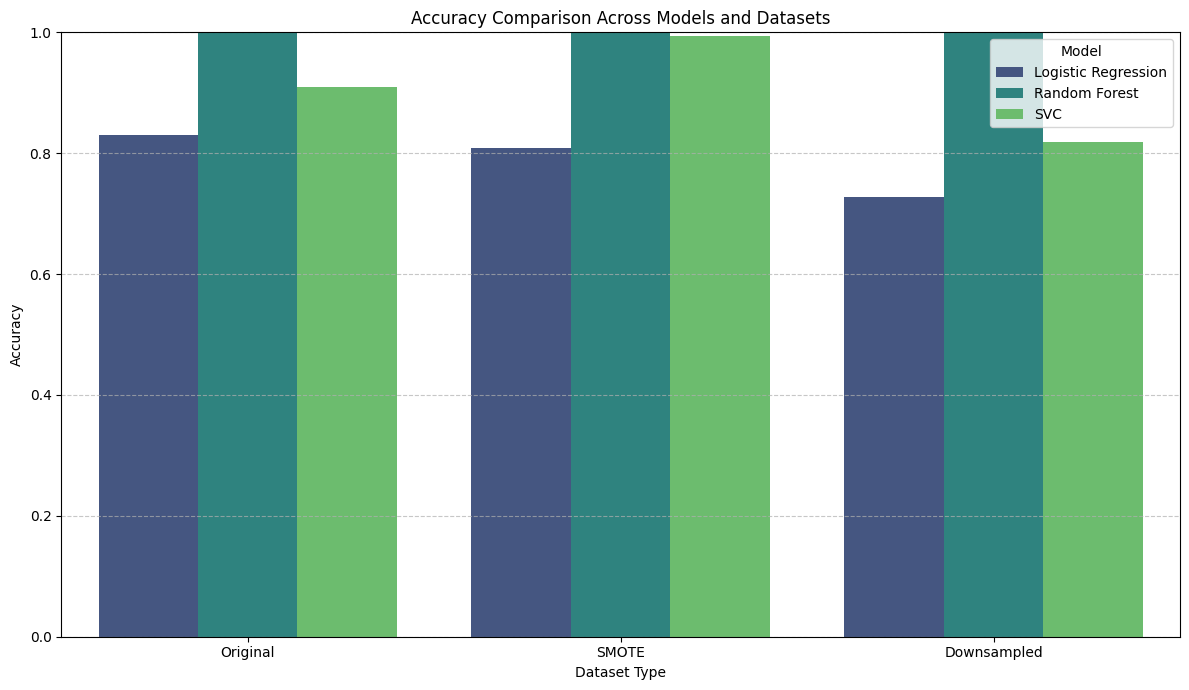

In [ ]:
# Accuracy Comparison Across Models and Datasets
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))
sns.barplot(x='Dataset', y='Accuracy', hue='Model', data=results_df, palette='viridis')
plt.title('Accuracy Comparison Across Models and Datasets')
plt.xlabel('Dataset Type')
plt.ylabel('Accuracy')
plt.ylim(0, 1) # Accuracy ranges from 0 to 1
plt.legend(title='Model')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

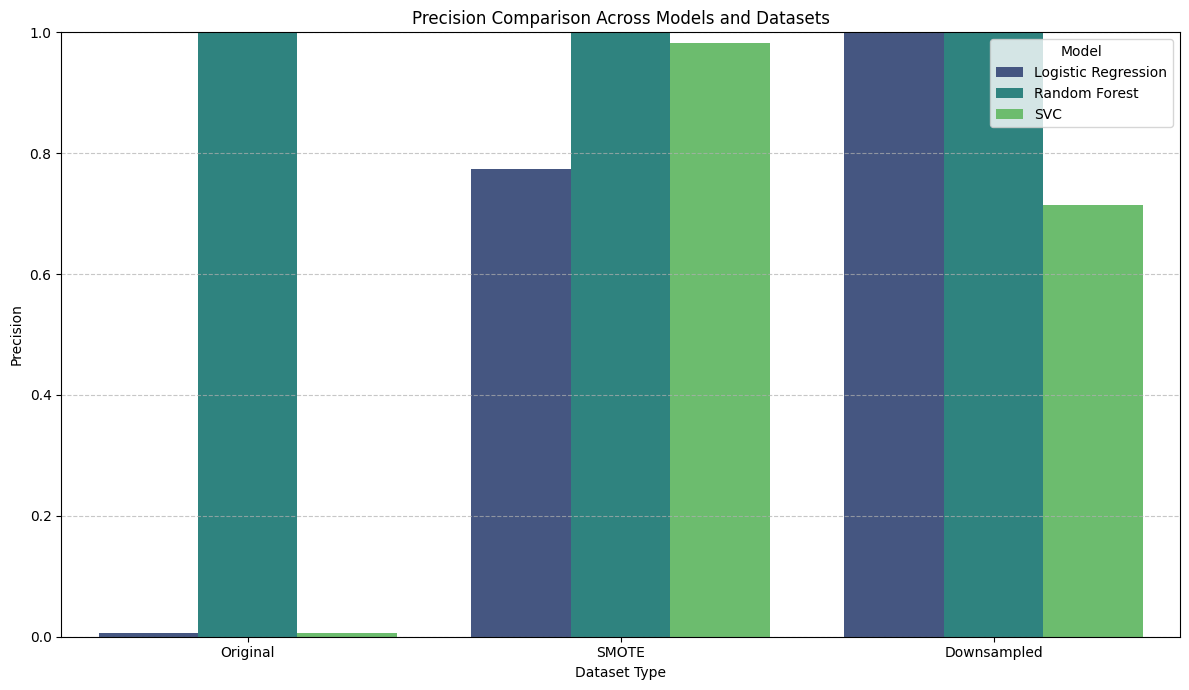

In [ ]:
# Precision Comparison Across Models and Datasets
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))
sns.barplot(x='Dataset', y='Precision', hue='Model', data=results_df, palette='viridis')
plt.title('Precision Comparison Across Models and Datasets')
plt.xlabel('Dataset Type')
plt.ylabel('Precision')
plt.ylim(0, 1) # Precision ranges from 0 to 1
plt.legend(title='Model')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

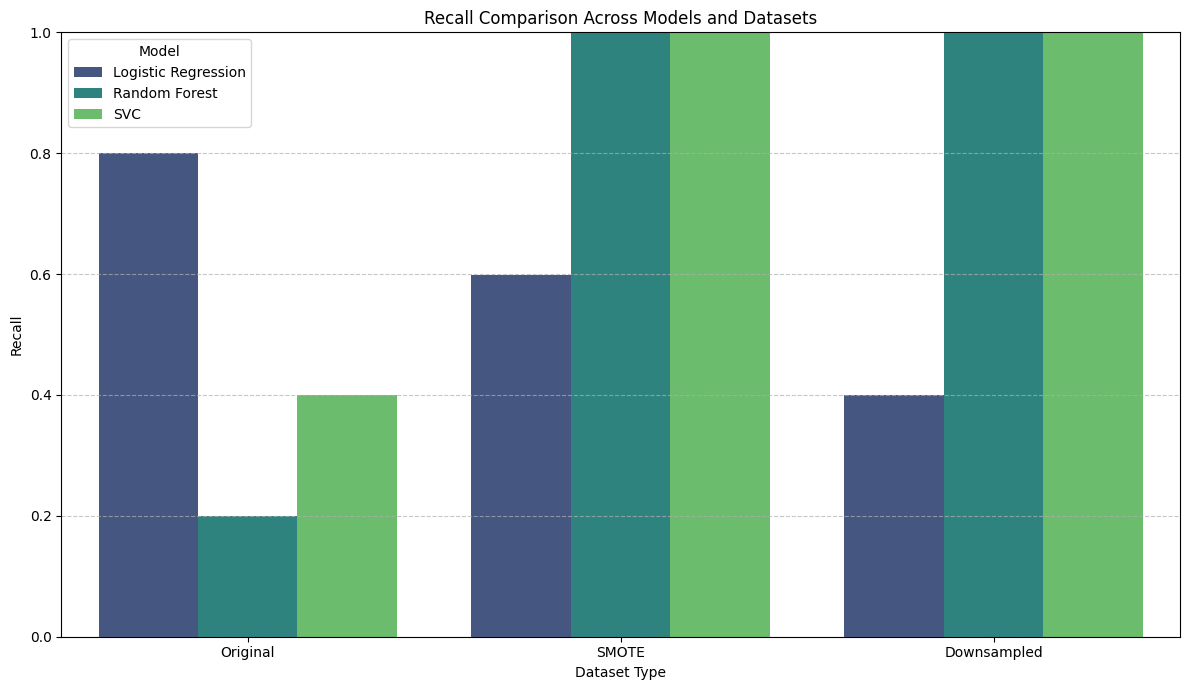

In [ ]:
# Recall Comparison Across Models and Datasets
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))
sns.barplot(x='Dataset', y='Recall', hue='Model', data=results_df, palette='viridis')
plt.title('Recall Comparison Across Models and Datasets')
plt.xlabel('Dataset Type')
plt.ylabel('Recall')
plt.ylim(0, 1) # Recall ranges from 0 to 1
plt.legend(title='Model')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

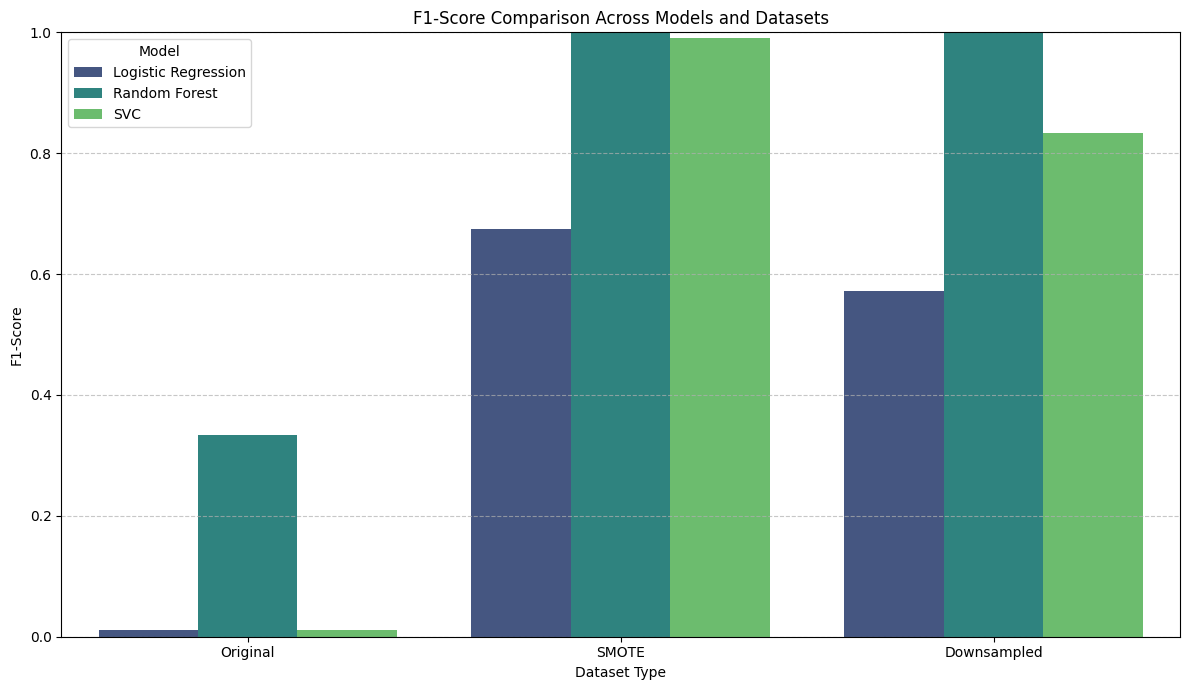

In [ ]:
# F1-SCORE GRAPHICAL REPRESENTATION

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))
sns.barplot(x='Dataset', y='F1-Score', hue='Model', data=results_df, palette='viridis')
plt.title('F1-Score Comparison Across Models and Datasets')
plt.xlabel('Dataset Type')
plt.ylabel('F1-Score')
plt.ylim(0, 1) # F1-Score ranges from 0 to 1
plt.legend(title='Model')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

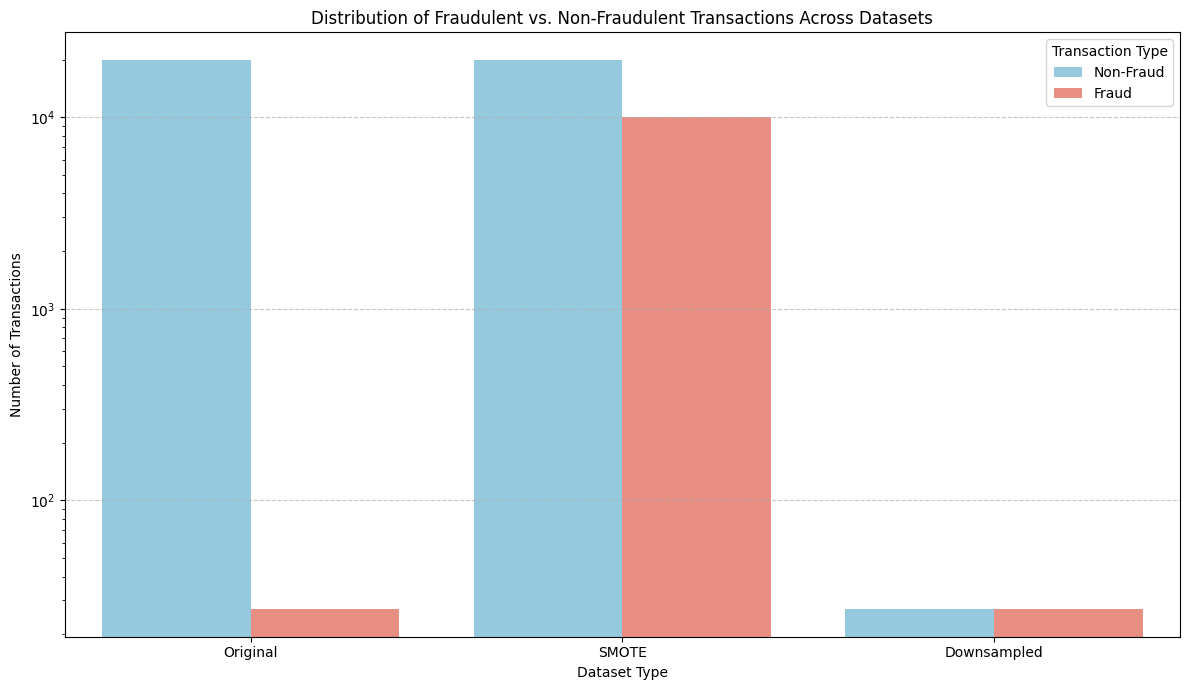

In [ ]:
# Transaction Distribution Across Datasets
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Prepare data for plotting
original_counts = df['Is Fraud?'].value_counts().reset_index()
original_counts.columns = ['Is Fraud?', 'Count']
original_counts['Dataset Type'] = 'Original'

smote_counts = df_resampled['Is Fraud?'].value_counts().reset_index()
smote_counts.columns = ['Is Fraud?', 'Count']
smote_counts['Dataset Type'] = 'SMOTE'

downsampled_counts = y_downsampled.value_counts().reset_index()
downsampled_counts.columns = ['Is Fraud?', 'Count']
downsampled_counts['Dataset Type'] = 'Downsampled'

# Combine all counts into a single DataFrame
combined_counts_df = pd.concat([original_counts, smote_counts, downsampled_counts])

# Map 'Is Fraud?' to 'Non-Fraud' and 'Fraud' for better readability
combined_counts_df['Is Fraud?'] = combined_counts_df['Is Fraud?'].map({0: 'Non-Fraud', 1: 'Fraud'})

# Create the bar plot
plt.figure(figsize=(12, 7))
sns.barplot(x='Dataset Type', y='Count', hue='Is Fraud?', data=combined_counts_df, palette={'Non-Fraud': 'skyblue', 'Fraud': 'salmon'})
plt.title('Distribution of Fraudulent vs. Non-Fraudulent Transactions Across Datasets')
plt.xlabel('Dataset Type')
plt.ylabel('Number of Transactions')
plt.yscale('log') # Use a log scale due to large differences in counts
plt.legend(title='Transaction Type')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# Grid Search for Model Optimization on Downsampled Data to get the best possible performance from each model given the adjusted class balance.
# Initialize an empty list to store grid search results. This ensures it's reset only once.
results_gs = []

In [ ]:
from sklearn.model_selection import GridSearchCV

# Logistic Regression Grid Search
print("\n--- Performing Grid Search for Logistic Regression ---")
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2']
}
# Ensure solver is compatible with chosen penalties
# 'liblinear' supports both 'l1' and 'l2'
# 'saga' also supports both but can be slower
grid_search_lr = GridSearchCV(LogisticRegression(random_state=42, solver='liblinear', class_weight='balanced'),
                            param_grid_lr, cv=3, scoring='f1', verbose=1, n_jobs=-1)
grid_search_lr.fit(X_train_downsampled, y_train_downsampled)

best_lr = grid_search_lr.best_estimator_
print(f"Best Logistic Regression Parameters: {grid_search_lr.best_params_}")
print(f"Best Logistic Regression F1-Score (CV): {grid_search_lr.best_score_:.4f}")

results_gs.append(train_evaluate_model(
    best_lr, X_train_downsampled, y_train_downsampled, X_test_downsampled, y_test_downsampled,
    'Logistic Regression (GS)', 'Downsampled'
))

# --- Random Forest Grid Search ---
print("\n--- Performing Grid Search for Random Forest ---")
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5]
}
grid_search_rf = GridSearchCV(RandomForestClassifier(random_state=42, class_weight='balanced'),
                            param_grid_rf, cv=3, scoring='f1', verbose=1, n_jobs=-1)
grid_search_rf.fit(X_train_downsampled, y_train_downsampled)

best_rf = grid_search_rf.best_estimator_
print(f"Best Random Forest Parameters: {grid_search_rf.best_params_}")
print(f"Best Random Forest F1-Score (CV): {grid_search_rf.best_score_:.4f}")

results_gs.append(train_evaluate_model(
    best_rf, X_train_downsampled, y_train_downsampled, X_test_downsampled, y_test_downsampled,
    'Random Forest (GS)', 'Downsampled'
))

# --- SVC Grid Search ---
print("\n--- Performing Grid Search for SVC ---")
param_grid_svc = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf']
}
grid_search_svc = GridSearchCV(SVC(random_state=42, probability=True, class_weight='balanced'),
                             param_grid_svc, cv=3, scoring='f1', verbose=1, n_jobs=-1)
grid_search_svc.fit(X_train_downsampled, y_train_downsampled)

best_svc = grid_search_svc.best_estimator_
print(f"Best SVC Parameters: {grid_search_svc.best_params_}")
print(f"Best SVC F1-Score (CV): {grid_search_svc.best_score_:.4f}")

results_gs.append(train_evaluate_model(
    best_svc, X_train_downsampled, y_train_downsampled, X_test_downsampled, y_test_downsampled,
    'SVC (GS)', 'Downsampled'
))


--- Performing Grid Search for Logistic Regression ---
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Logistic Regression Parameters: {'C': 10, 'penalty': 'l2'}
Best Logistic Regression F1-Score (CV): 0.6969

--- Training and Evaluating Logistic Regression (GS) on Downsampled Data ---
Accuracy: 0.8182
Precision: 1.0000
Recall: 0.6000
F1-Score: 0.7500
ROC AUC: 0.7333
Confusion Matrix:
 [[6 0]
 [2 3]]

--- Performing Grid Search for Random Forest ---
Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best Random Forest Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}
Best Random Forest F1-Score (CV): 0.7983

--- Training and Evaluating Random Forest (GS) on Downsampled Data ---
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1-Score: 1.0000
ROC AUC: 1.0000
Confusion Matrix:
 [[6 0]
 [0 5]]

--- Performing Grid Search for SVC ---
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best SVC Parameters: {'C': 10, 'kernel': 

In [ ]:
# Grid Search Results Summary
import pandas as pd

results_gs_df = pd.DataFrame(results_gs)
display(results_gs_df)

,Model,Dataset,Accuracy,Precision,Recall,F1-Score,ROC AUC
0,Logistic Regression (GS),Downsampled,0.818182,1.0,0.6,0.750000,0.733333
1,Random Forest (GS),Downsampled,1.000000,1.0,1.0,1.000000,1.000000
2,SVC (GS),Downsampled,0.909091,1.0,0.8,0.888889,0.900000


/tmp/ipykernel_3523/1729285819.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Accuracy', data=results_gs_df, palette='viridis')


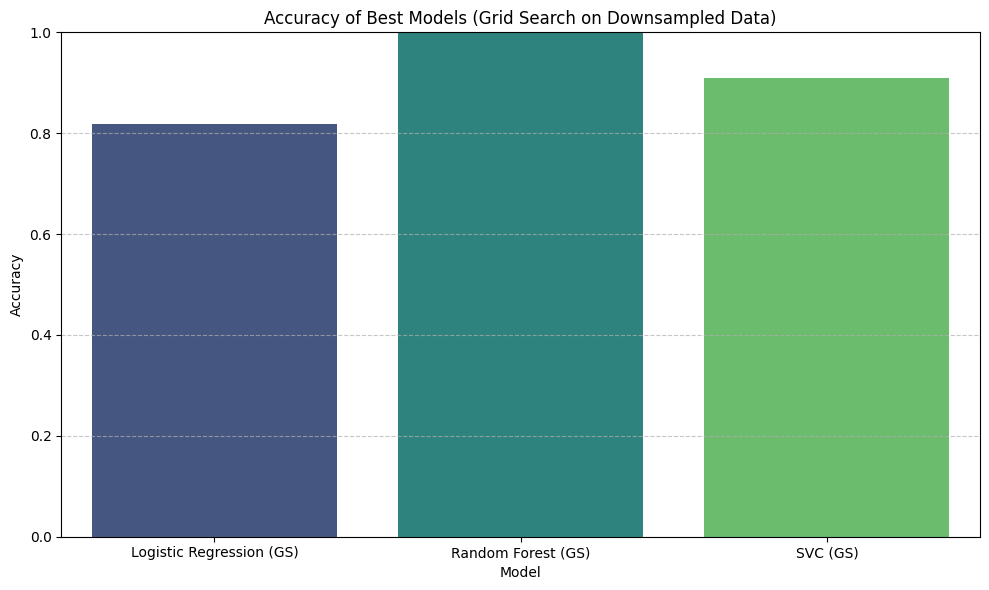

In [ ]:
# Accuracy Comparison (Grid Search Models)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(x='Model', y='Accuracy', data=results_gs_df, palette='viridis')
plt.title('Accuracy of Best Models (Grid Search on Downsampled Data)')
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/tmp/ipykernel_3523/3039365512.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Precision', data=results_gs_df, palette='viridis')


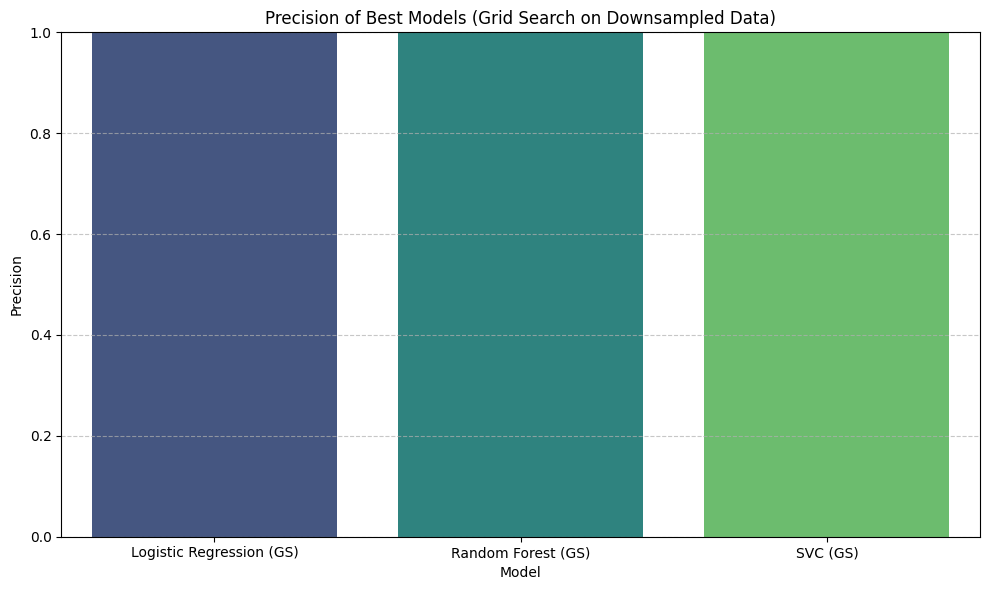

In [ ]:
# Precision Comparison (Grid Search Models)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(x='Model', y='Precision', data=results_gs_df, palette='viridis')
plt.title('Precision of Best Models (Grid Search on Downsampled Data)')
plt.xlabel('Model')
plt.ylabel('Precision')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/tmp/ipykernel_3523/1065507280.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Recall', data=results_gs_df, palette='viridis')


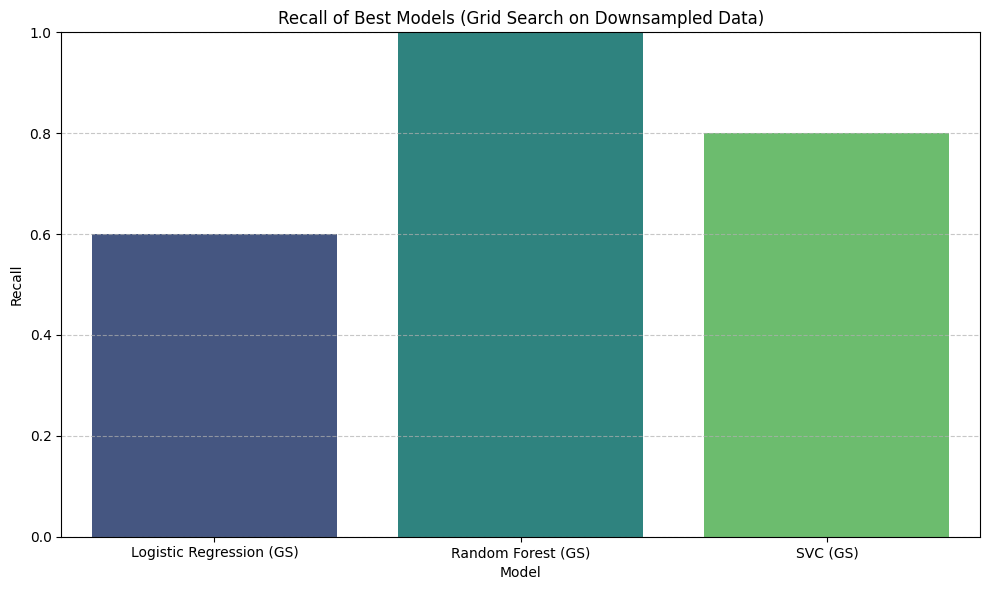

In [ ]:
# Recall Comparison (Grid Search Models)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(x='Model', y='Recall', data=results_gs_df, palette='viridis')
plt.title('Recall of Best Models (Grid Search on Downsampled Data)')
plt.xlabel('Model')
plt.ylabel('Recall')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/tmp/ipykernel_3523/2856502288.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='F1-Score', data=results_gs_df, palette='viridis')


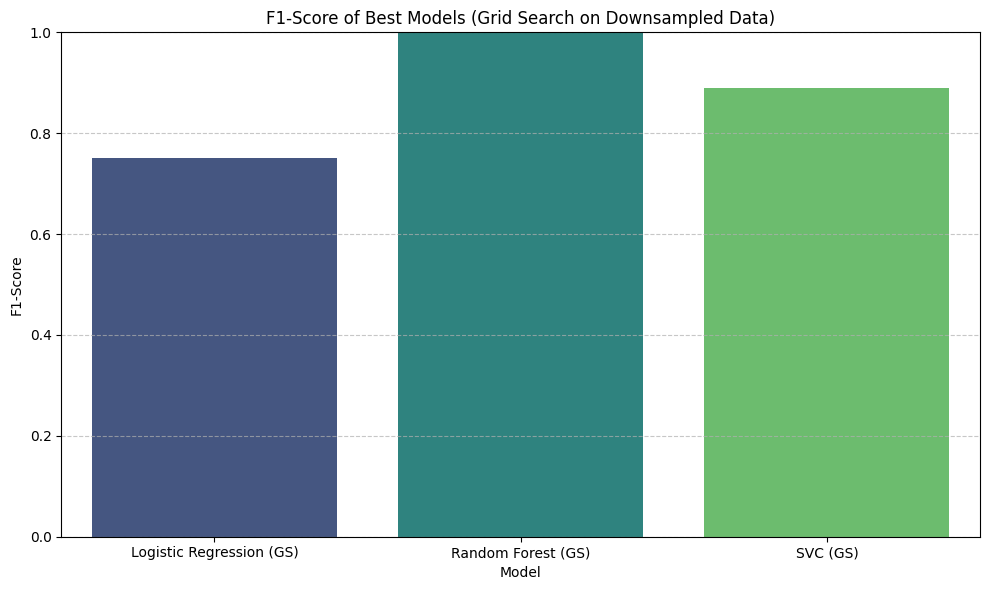

In [ ]:
# F1-Score Comparison (Grid Search Models)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(x='Model', y='F1-Score', data=results_gs_df, palette='viridis')
plt.title('F1-Score of Best Models (Grid Search on Downsampled Data)')
plt.xlabel('Model')
plt.ylabel('F1-Score')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# Grid Search for Model Optimization on SMOTE Data
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Clear previous grid search results if this cell is meant to focus ONLY on SMOTE
# Assuming `results_gs` is a global list that was populated in a previous cell.
global results_gs
results_gs = []

# --- Logistic Regression Grid Search (SMOTE Data) ---
print("\n--- Performing Grid Search for Logistic Regression on SMOTE Data ---")
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2']
}
# Ensure solver is compatible with chosen penalties
# 'liblinear' supports both 'l1' and 'l2'
grid_search_lr_smote = GridSearchCV(LogisticRegression(random_state=42, solver='liblinear'),
                                   param_grid_lr, cv=3, scoring='f1', verbose=1, n_jobs=-1)
grid_search_lr_smote.fit(X_train_smote, y_train_smote)

best_lr_smote = grid_search_lr_smote.best_estimator_
print(f"Best Logistic Regression Parameters (SMOTE): {grid_search_lr_smote.best_params_}")
print(f"Best Logistic Regression F1-Score (CV, SMOTE): {grid_search_lr_smote.best_score_:.4f}")

results_gs.append(train_evaluate_model(
    best_lr_smote, X_train_smote, y_train_smote, X_test_smote, y_test_smote,
    'Logistic Regression (GS)', 'SMOTE'
))

# --- Random Forest Grid Search (SMOTE Data) ---
print("\n--- Performing Grid Search for Random Forest on SMOTE Data ---")
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5]
}
grid_search_rf_smote = GridSearchCV(RandomForestClassifier(random_state=42),
                                   param_grid_rf, cv=3, scoring='f1', verbose=1, n_jobs=-1)
grid_search_rf_smote.fit(X_train_smote, y_train_smote)

best_rf_smote = grid_search_rf_smote.best_estimator_
print(f"Best Random Forest Parameters (SMOTE): {grid_search_rf_smote.best_params_}")
print(f"Best Random Forest F1-Score (CV, SMOTE): {grid_search_rf_smote.best_score_:.4f}")

results_gs.append(train_evaluate_model(
    best_rf_smote, X_train_smote, y_train_smote, X_test_smote, y_test_smote,
    'Random Forest (GS)', 'SMOTE'
))

# --- SVC Grid Search (SMOTE Data) ---
print("\n--- Performing Grid Search for SVC on SMOTE Data ---")
param_grid_svc = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf']
}
grid_search_svc_smote = GridSearchCV(SVC(random_state=42, probability=True),
                                    param_grid_svc, cv=3, scoring='f1', verbose=1, n_jobs=-1)
grid_search_svc_smote.fit(X_train_smote, y_train_smote)

best_svc_smote = grid_search_svc_smote.best_estimator_
print(f"Best SVC Parameters (SMOTE): {grid_search_svc_smote.best_params_}")
print(f"Best SVC F1-Score (CV, SMOTE): {grid_search_svc_smote.best_score_:.4f}")

results_gs.append(train_evaluate_model(
    best_svc_smote, X_train_smote, y_train_smote, X_test_smote, y_test_smote,
    'SVC (GS)', 'SMOTE'
))

# Recreate results_gs_df with only SMOTE data
results_gs_df = pd.DataFrame(results_gs)
display(results_gs_df) # Display the DataFrame

# Now plot the results for SMOTE data
plt.figure(figsize=(10, 6))
# Filter for SMOTE data only, to ensure plot reflects the requested change
sns.barplot(x='Model', y='Accuracy', data=results_gs_df[results_gs_df['Dataset'] == 'SMOTE'], palette='viridis')
plt.title('Accuracy of Best Models (Grid Search on SMOTE Data)')
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


--- Performing Grid Search for Logistic Regression on SMOTE Data ---
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Logistic Regression Parameters (SMOTE): {'C': 0.1, 'penalty': 'l1'}
Best Logistic Regression F1-Score (CV, SMOTE): 0.6800

--- Training and Evaluating Logistic Regression (GS) on SMOTE Data ---
Accuracy: 0.8101
Precision: 0.7797
Recall: 0.5998
F1-Score: 0.6780
ROC AUC: 0.9093
Confusion Matrix:
 [[3649  338]
 [ 798 1196]]

--- Performing Grid Search for Random Forest on SMOTE Data ---
Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best Random Forest Parameters (SMOTE): {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
Best Random Forest F1-Score (CV, SMOTE): 0.9997

--- Training and Evaluating Random Forest (GS) on SMOTE Data ---
Accuracy: 0.9998
Precision: 1.0000
Recall: 0.9995
F1-Score: 0.9997
ROC AUC: 1.0000
Confusion Matrix:
 [[3987    0]
 [   1 1993]]

--- Performing Grid Search for SVC on SMOTE Data ---
Fitting 3 folds

In [ ]:
# K-FOLD CROSS VALIDATION FOR MODEL EVAULATION
from sklearn.model_selection import KFold, cross_val_score

def perform_kfold_cv(model, X, y, model_name, dataset_type, n_splits=5):
    """Performs K-Fold Cross-Validation and returns mean/std of scores."""
    print(f"\n--- Performing K-Fold CV for {model_name} on {dataset_type} Data ---")
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

    # Use 'roc_auc' as it's a good metric for imbalanced datasets and binary classification
    # 'f1' is also a good choice, but ROC AUC gives a broader view of classifier performance
    scoring = 'roc_auc'

    # Some models like SVC with probability=True need a pipeline for cross_val_score for consistency
    # However, for LogisticRegression and RandomForestClassifier, it's generally fine directly.
    # For this exercise, assuming models are already initialized appropriately for proba output.

    try:
        scores = cross_val_score(model, X, y, cv=kf, scoring=scoring, n_jobs=-1)
        print(f"  {scoring.replace('_', ' ').title()} Scores: {scores}")
        print(f"  Mean {scoring.replace('_', ' ').title()}: {scores.mean():.4f}")
        print(f"  Std Dev {scoring.replace('_', ' ').title()}: {scores.std():.4f}")
        return {
            'Model': model_name,
            'Dataset': dataset_type,
            'Metric': scoring,
            'Mean Score': scores.mean(),
            'Std Dev': scores.std()
        }
    except Exception as e:
        print(f"  Error during CV for {model_name} on {dataset_type}: {e}")
        return {
            'Model': model_name,
            'Dataset': dataset_type,
            'Metric': scoring,
            'Mean Score': None,
            'Std Dev': None,
            'Error': str(e)
        }

kf_cv_results = []

In [ ]:
# K-Fold CV for Logistic Regression
# Original Data
log_reg_original_kf = LogisticRegression(random_state=42, solver='liblinear', class_weight='balanced')
kf_cv_results.append(perform_kfold_cv(log_reg_original_kf, X_original, y_original, 'Logistic Regression', 'Original'))

# SMOTE Data (using the X_resampled, y_resampled from earlier SMOTE cell)
log_reg_smote_kf = LogisticRegression(random_state=42, solver='liblinear')
kf_cv_results.append(perform_kfold_cv(log_reg_smote_kf, X_resampled, y_resampled, 'Logistic Regression', 'SMOTE'))

# Downsampled Data (using X_downsampled, y_downsampled from earlier undersampling cell)
log_reg_downsampled_kf = LogisticRegression(random_state=42, solver='liblinear')
kf_cv_results.append(perform_kfold_cv(log_reg_downsampled_kf, X_downsampled, y_downsampled, 'Logistic Regression', 'Downsampled'))

# K-Fold CV for Random Forest
# Original Data
rand_forest_original_kf = RandomForestClassifier(random_state=42, class_weight='balanced')
kf_cv_results.append(perform_kfold_cv(rand_forest_original_kf, X_original, y_original, 'Random Forest', 'Original'))

# SMOTE Data
rand_forest_smote_kf = RandomForestClassifier(random_state=42)
kf_cv_results.append(perform_kfold_cv(rand_forest_smote_kf, X_resampled, y_resampled, 'Random Forest', 'SMOTE'))

# Downsampled Data
rand_forest_downsampled_kf = RandomForestClassifier(random_state=42, class_weight='balanced')
kf_cv_results.append(perform_kfold_cv(rand_forest_downsampled_kf, X_downsampled, y_downsampled, 'Random Forest', 'Downsampled'))

# K-Fold CV for SVC
# Original Data
# SVC can be slow, especially with probability=True and a large dataset.
# We will use it for the original dataset, but keep in mind performance.
svc_original_kf = SVC(random_state=42, probability=True, class_weight='balanced')
kf_cv_results.append(perform_kfold_cv(svc_original_kf, X_original, y_original, 'SVC', 'Original'))

# SMOTE Data
svc_smote_kf = SVC(random_state=42, probability=True)
kf_cv_results.append(perform_kfold_cv(svc_smote_kf, X_resampled, y_resampled, 'SVC', 'SMOTE'))

# Downsampled Data
svc_downsampled_kf = SVC(random_state=42, probability=True, class_weight='balanced')
kf_cv_results.append(perform_kfold_cv(svc_downsampled_kf, X_downsampled, y_downsampled, 'SVC', 'Downsampled'))

# Display results
kf_cv_results_df = pd.DataFrame(kf_cv_results)
display(kf_cv_results_df)


--- Performing K-Fold CV for Logistic Regression on Original Data ---
  Roc Auc Scores: [0.93776107 0.96708438 0.80300176 0.91085757 0.87173313]
  Mean Roc Auc: 0.8981
  Std Dev Roc Auc: 0.0570

--- Performing K-Fold CV for Logistic Regression on SMOTE Data ---
  Roc Auc Scores: [0.85296107 0.85354654 0.85522402 0.86151083 0.86402379]
  Mean Roc Auc: 0.8575
  Std Dev Roc Auc: 0.0045

--- Performing K-Fold CV for Logistic Regression on Downsampled Data ---
  Roc Auc Scores: [0.73333333 0.63333333 0.93333333 0.63333333 0.72      ]
  Mean Roc Auc: 0.7307
  Std Dev Roc Auc: 0.1097

--- Performing K-Fold CV for Random Forest on Original Data ---
  Roc Auc Scores: [0.99995823 1.         0.91350582 0.99952984 0.99922247]
  Mean Roc Auc: 0.9824
  Std Dev Roc Auc: 0.0345

--- Performing K-Fold CV for Random Forest on SMOTE Data ---
  Roc Auc Scores: [0.99999987 0.99999987 1.         0.99999899 0.99999988]
  Mean Roc Auc: 1.0000
  Std Dev Roc Auc: 0.0000

--- Performing K-Fold CV for Random For

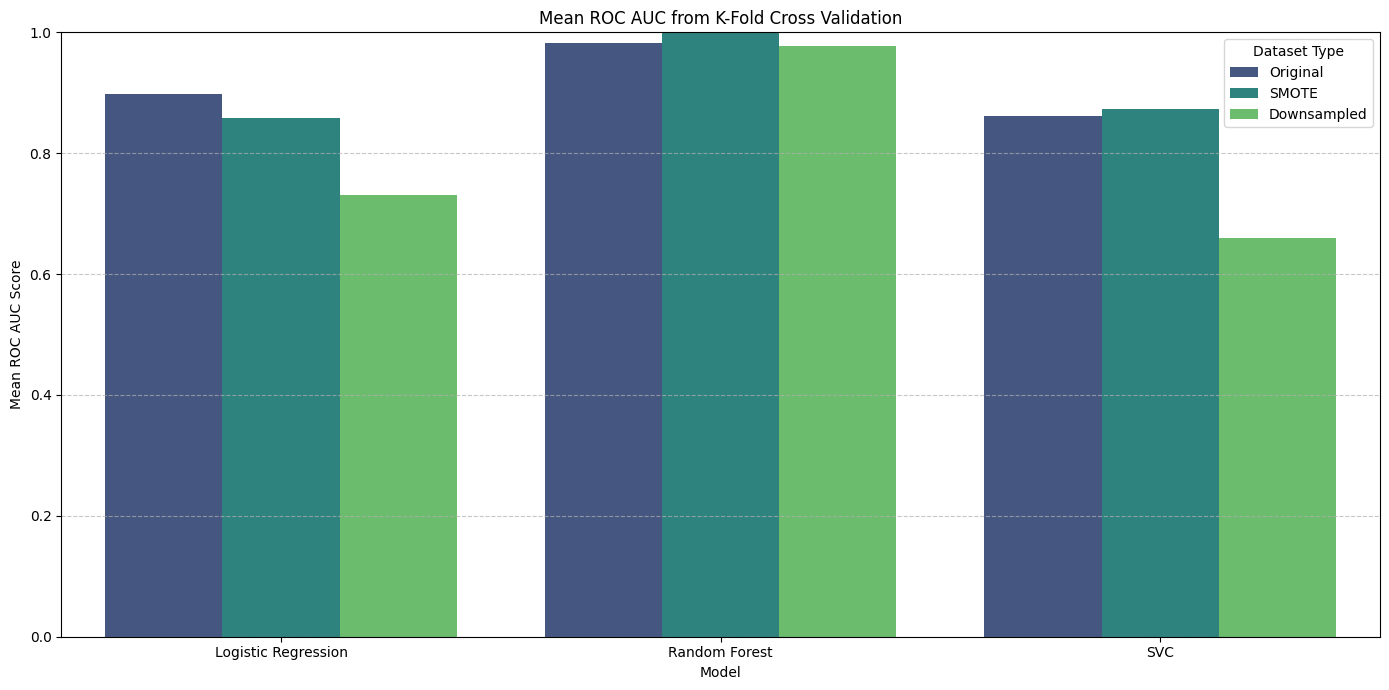

In [ ]:
# K-Fold Cross Validation Results
plt.figure(figsize=(14, 7))
sns.barplot(x='Model', y='Mean Score', hue='Dataset', data=kf_cv_results_df, palette='viridis')
plt.title('Mean ROC AUC from K-Fold Cross Validation')
plt.xlabel('Model')
plt.ylabel('Mean ROC AUC Score')
plt.ylim(0, 1) # ROC AUC ranges from 0 to 1
plt.legend(title='Dataset Type')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

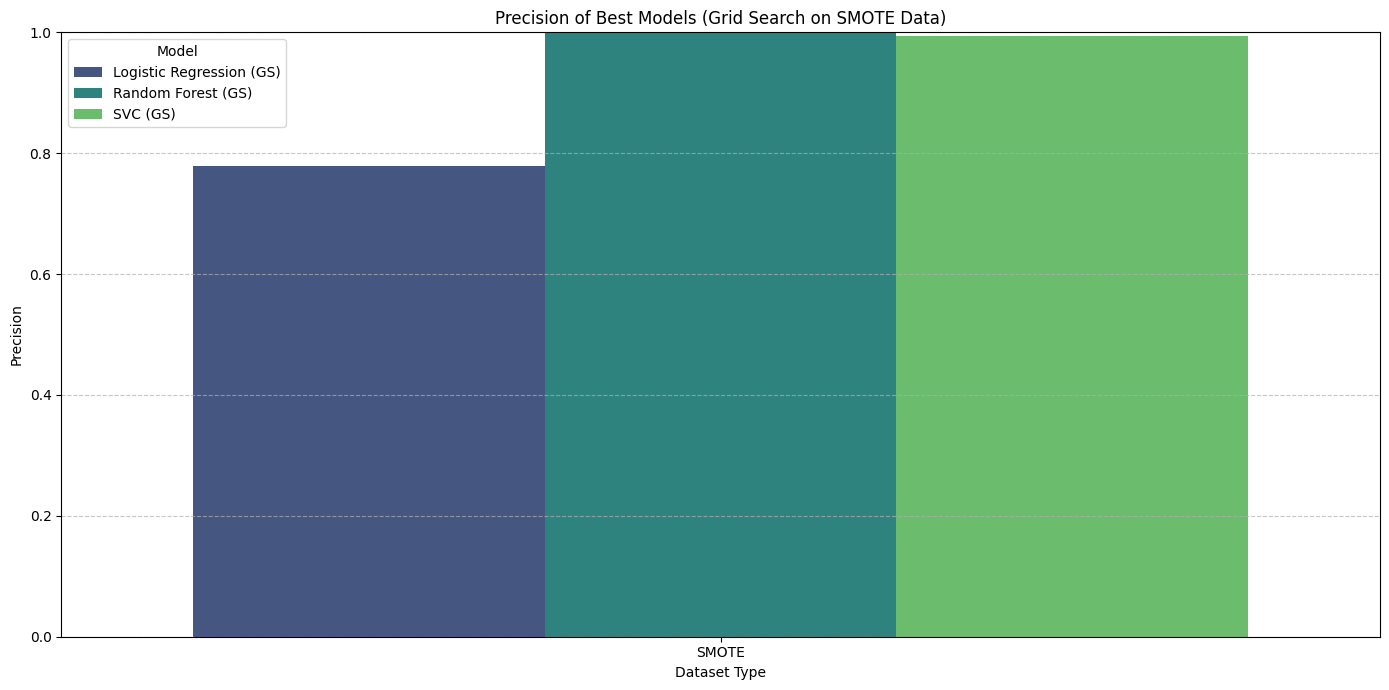

In [ ]:
# Precision Comparison (All Grid Search Models)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))
sns.barplot(x='Dataset', y='Precision', hue='Model', data=results_gs_df, palette='viridis')
plt.title('Precision of Best Models (Grid Search on SMOTE Data)')
plt.xlabel('Dataset Type')
plt.ylabel('Precision')
plt.ylim(0, 1)
plt.legend(title='Model')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

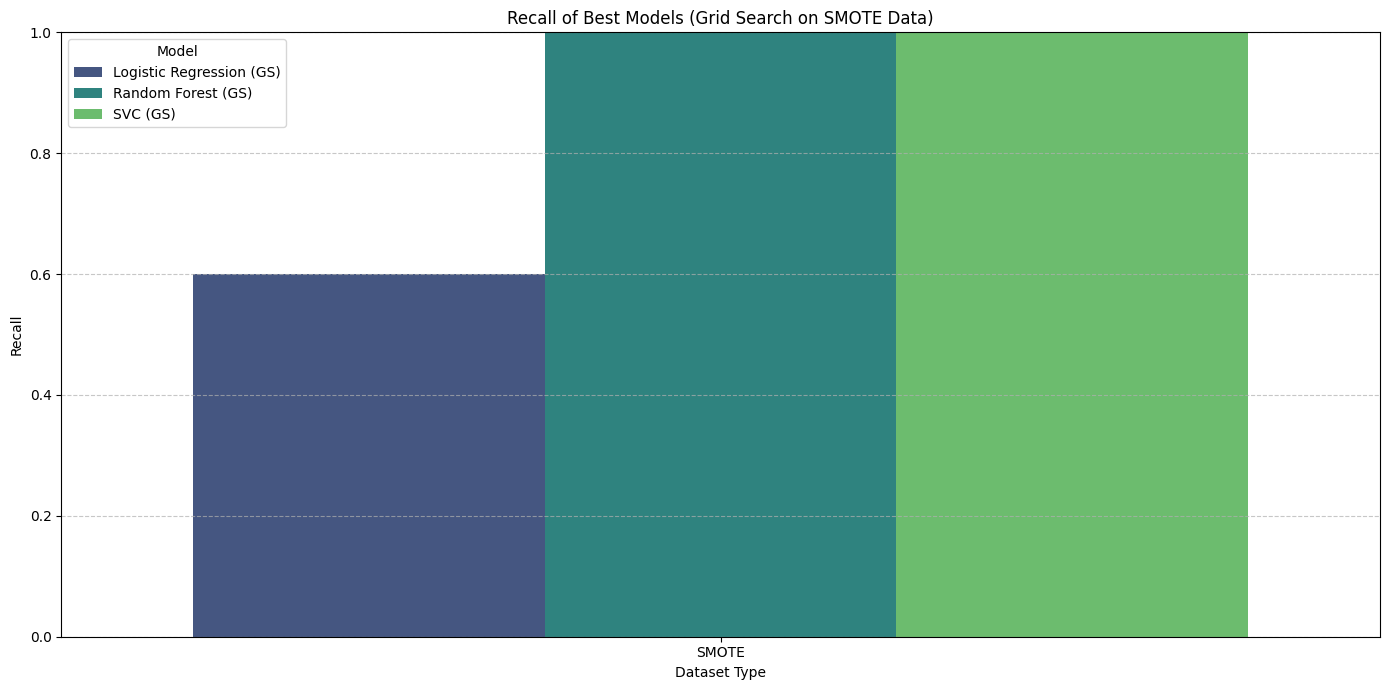

In [ ]:
# Recall Comparison (All Grid Search Models)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))
sns.barplot(x='Dataset', y='Recall', hue='Model', data=results_gs_df, palette='viridis')
plt.title('Recall of Best Models (Grid Search on SMOTE Data)')
plt.xlabel('Dataset Type')
plt.ylabel('Recall')
plt.ylim(0, 1)
plt.legend(title='Model')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

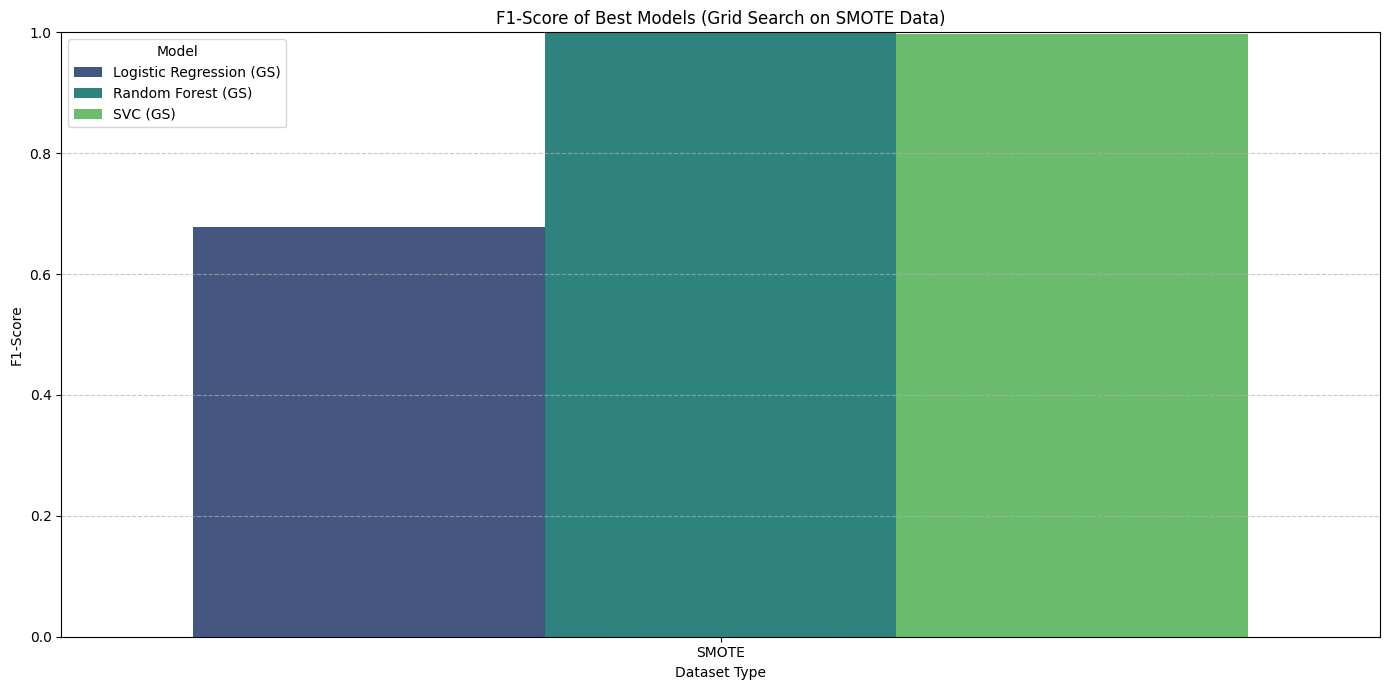

In [ ]:
# F1-Score Comparison (All Grid Search Models)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))
sns.barplot(x='Dataset', y='F1-Score', hue='Model', data=results_gs_df, palette='viridis')
plt.title('F1-Score of Best Models (Grid Search on SMOTE Data)')
plt.xlabel('Dataset Type')
plt.ylabel('F1-Score')
plt.ylim(0, 1)
plt.legend(title='Model')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# COST MATRIX ANALYSIS
# For fraud detection, False Negatives (FN - actual fraud classified as non-fraud)
# are typically much more costly than False Positives (FP - non-fraud classified as fraud).
# We will define a custom cost matrix to evaluate the financial impact of each model's predictions.

# Let's assume the following costs:
# False Negative (FN): Cost = 1000 (representing the financial loss from an undetected fraudulent transaction)
# False Positive (FP): Cost = 10 (representing the cost of investigating a legitimate transaction, e.g., customer inconvenience, operational overhead)
# True Negative (TN): Cost = 0 (correctly identified non-fraud)
# True Positive (TP): Cost = 0 (correctly identified fraud)

def calculate_cost(conf_matrix, cost_fn=1000, cost_fp=10):
    """Calculates the total cost based on the confusion matrix and specified costs.
    conf_matrix should be in the format: [[TN, FP], [FN, TP]]
    """
    tn, fp, fn, tp = conf_matrix.ravel()
    total_cost = (fn * cost_fn) + (fp * cost_fp)
    return total_cost

# Re-run train_evaluate_model to store confusion matrices

def train_evaluate_model_with_cm(model, X_train, y_train, X_test, y_test, model_name, dataset_type):
    """Trains a model and evaluates it, returning metrics and confusion matrix."""
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_proba) if y_proba is not None else 'N/A'

    cm = confusion_matrix(y_test, y_pred)

    return {
        'Model': model_name,
        'Dataset': dataset_type,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'ROC AUC': roc_auc,
        'Confusion Matrix': cm
    }

In [ ]:
# Re-collect results with confusion matrices
new_results = []

# --- Logistic Regression --- #
log_reg_original = LogisticRegression(random_state=42, solver='liblinear', class_weight='balanced')
new_results.append(train_evaluate_model_with_cm(
    log_reg_original, X_train_original, y_train_original, X_test_original, y_test_original,
    'Logistic Regression', 'Original'
))

log_reg_smote = LogisticRegression(random_state=42, solver='liblinear')
new_results.append(train_evaluate_model_with_cm(
    log_reg_smote, X_train_smote, y_train_smote, X_test_smote, y_test_smote,
    'Logistic Regression', 'SMOTE'
))

log_reg_downsampled = LogisticRegression(random_state=42, solver='liblinear')
new_results.append(train_evaluate_model_with_cm(
    log_reg_downsampled, X_train_downsampled, y_train_downsampled, X_test_downsampled, y_test_downsampled,
    'Logistic Regression', 'Downsampled'
))

# --- Random Forest --- #
rand_forest_original = RandomForestClassifier(random_state=42, class_weight='balanced')
new_results.append(train_evaluate_model_with_cm(
    rand_forest_original, X_train_original, y_train_original, X_test_original, y_test_original,
    'Random Forest', 'Original'
))

rand_forest_smote = RandomForestClassifier(random_state=42)
new_results.append(train_evaluate_model_with_cm(
    rand_forest_smote, X_train_smote, y_train_smote, X_test_smote, y_test_smote,
    'Random Forest', 'SMOTE'
))

rand_forest_downsampled = RandomForestClassifier(random_state=42, class_weight='balanced')
new_results.append(train_evaluate_model_with_cm(
    rand_forest_downsampled, X_train_downsampled, y_train_downsampled, X_test_downsampled, y_test_downsampled,
    'Random Forest', 'Downsampled'
))

# --- SVC --- #
svc_original = SVC(random_state=42, probability=True, class_weight='balanced')
new_results.append(train_evaluate_model_with_cm(
    svc_original, X_train_original, y_train_original, X_test_original, y_test_original,
    'SVC', 'Original'
))

svc_smote = SVC(random_state=42, probability=True)
new_results.append(train_evaluate_model_with_cm(
    svc_smote, X_train_smote, y_train_smote, X_test_smote, y_test_smote,
    'SVC', 'SMOTE'
))

svc_downsampled = SVC(random_state=42, probability=True, class_weight='balanced')
new_results.append(train_evaluate_model_with_cm(
    svc_downsampled, X_train_downsampled, y_train_downsampled, X_test_downsampled, y_test_downsampled,
    'SVC', 'Downsampled'
))

# Calculate costs and add to new_results
for res in new_results:
    res['Total Cost'] = calculate_cost(res['Confusion Matrix'])

# Create a new DataFrame for cost analysis
cost_df = pd.DataFrame(new_results)

print("Cost Matrix Analysis:")
display(cost_df[['Model', 'Dataset', 'Total Cost', 'Confusion Matrix']])

Cost Matrix Analysis:


,Model,Dataset,Total Cost,Confusion Matrix
0,Logistic Regression,Original,7500,"[[3338, 650], [1, 4]]"
1,Logistic Regression,SMOTE,802500,"[[3637, 350], [799, 1195]]"
2,Logistic Regression,Downsampled,3000,"[[6, 0], [3, 2]]"
3,Random Forest,Original,4000,"[[3988, 0], [4, 1]]"
4,Random Forest,SMOTE,1000,"[[3987, 0], [1, 1993]]"
5,Random Forest,Downsampled,0,"[[6, 0], [0, 5]]"
6,SVC,Original,6610,"[[3627, 361], [3, 2]]"
7,SVC,SMOTE,370,"[[3950, 37], [0, 1994]]"
8,SVC,Downsampled,20,"[[4, 2], [0, 5]]"


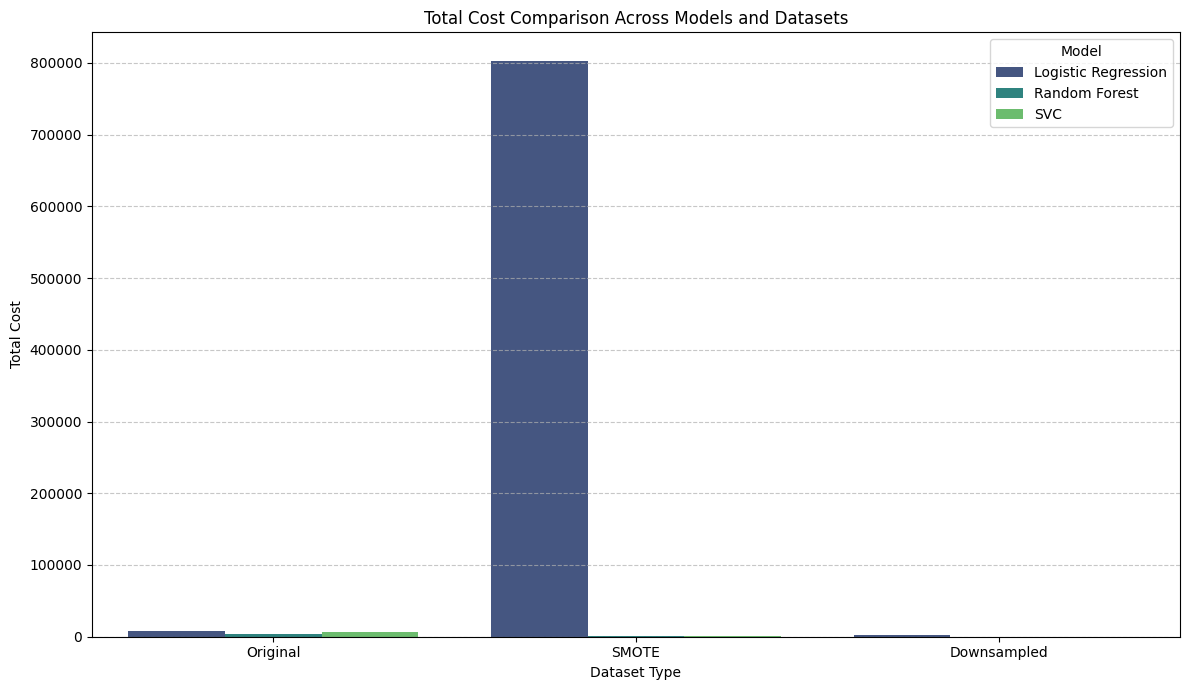

In [ ]:
# Total Cost Comparison Across Models and Datasets
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))
sns.barplot(x='Dataset', y='Total Cost', hue='Model', data=cost_df, palette='viridis')
plt.title('Total Cost Comparison Across Models and Datasets')
plt.xlabel('Dataset Type')
plt.ylabel('Total Cost')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()